# Character-Level Name Generation: Bigram vs. Trigram

This notebook implements a character-level linear language model with a configurable context size (`block_size`).

I compared two configurations:
- **Bigram:** `block_size=1`
- **Linear Trigram:** `block_size=2`

Unlike a full trigram model, the linear trigram combines the separate contributions of the two previous characters rather than learning a distinct effect for each pair.

I ran 24 training experiments with different learning rates, training steps, and regularization strengths. I selected the best configuration for each model using validation loss, evaluated both models on unseen test data, and compared the names they generated.

### Credits

This project started from Andrej Karpathy's *Building makemore* lecture and exercises.

**From Karpathy:** The names dataset, the core character-level modeling approach, and parts of the original encoding, training, and sampling code.

**My implementation:** A generalized model supporting variable context sizes, reusable training and evaluation functions, automated hyperparameter search, model selection, and a train/dev/test comparison pipeline.

**Original resources:**
- [Neural Networks: Zero to Hero](https://github.com/karpathy/nn-zero-to-hero)
- [Original makemore notebook](https://github.com/karpathy/nn-zero-to-hero/blob/master/lectures/makemore/makemore_part1_bigrams.ipynb)
- [Dataset](https://github.com/karpathy/makemore)

## 1. Imports & Setup

In [2]:
import torch
import random
import torch.nn.functional as F
from itertools import product
import matplotlib.pyplot as plt
import pandas as pd

## 2. Data Preparation

In [3]:
words = open('names.txt', 'r').read().splitlines()

chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}

# Split names into train, dev, and test sets
random.seed(42)
random.shuffle(words)

n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

train_words = words[:n1]
dev_words = words[n1:n2]
test_words = words[n2:]


## 3. Model Functions

In [4]:
def build_dataset(words, block_size=2):
  xs, ys = [], []
  for w in words:
    chs = block_size * ['.'] + list(w) + ['.']
    for window in zip(*(chs[i:] for i in range(block_size + 1))):
      encoded_window = []
      for i in range(len(window)):
        encoded_window.append(stoi[window[i]])
      xs.append(encoded_window[:-1])
      ys.append(encoded_window[-1])
  xs = torch.tensor(xs)
  ys = torch.tensor(ys)

  return xs, ys


def initialize_model(block_size, seed):
  g = torch.Generator().manual_seed(seed)
  W = torch.randn((27 * block_size, 27), generator=g, requires_grad=True)

  return W


# forward pass
def forward(xs, W):
  xenc = F.one_hot(xs, num_classes=27).flatten(start_dim=1).float() # input to the network: one-hot encoding
  logits = xenc @ W # predict log-counts

  return logits

def compute_loss(logits, ys, W, reg_strength=0.0):

  # Cross-entropy loss
  loss = F.cross_entropy(logits, ys) + reg_strength*(W**2).mean()

  return loss



def train_model(xs, ys, W, learning_rate, steps, reg_strength=0.0):
  loss_history = []
  for _ in range(steps):
    # forward pass
    logits = forward(xs, W)
    loss = compute_loss(logits , ys, W, reg_strength)
    loss_history.append(loss.item())
    # backward pass
    W.grad = None # Clear previous gradients
    loss.backward()

    # update
    with torch.no_grad():
      W -= learning_rate * W.grad

  return W, loss_history

def evaluate_model(xs, ys, W, reg_strength=0.0):
  with torch.no_grad():
    # forward pass
    logits = forward(xs, W)
    loss = compute_loss(logits , ys, W, reg_strength)

  return loss.item()


def run_experiment(train_words, dev_words, block_size, learning_rate,
                   steps, seed=2147483647, reg_strength=0.0,
                   eval_reg_strength=0.0):
  # Build train and dev datasets
  xs_train, ys_train = build_dataset(train_words, block_size=block_size)
  xs_dev, ys_dev = build_dataset(dev_words, block_size=block_size)

  # Initialize model weights
  W = initialize_model(block_size=block_size, seed=seed)

  # Train the model
  W, loss_history = train_model(
      xs=xs_train,
      ys=ys_train, W=W,
      learning_rate=learning_rate,
      steps=steps, reg_strength=reg_strength)

  # Evaluate on train and dev sets
  train_loss = evaluate_model(xs=xs_train, ys=ys_train, W=W,
                              reg_strength=eval_reg_strength)
  dev_loss = evaluate_model(xs=xs_dev, ys=ys_dev, W=W,
                            reg_strength=eval_reg_strength)

  # Return model and experiment results
  return W, loss_history, train_loss, dev_loss


def run_test(W, test_words, block_size):
    # Build test dataset
    xs_test, ys_test = build_dataset(test_words, block_size=block_size)

    test_loss = evaluate_model(xs=xs_test, ys=ys_test, W=W)

    return test_loss

@torch.no_grad()
def generate_names(W, block_size, generator, max_length=20):
  out = []
  context = torch.tensor([0] * block_size)

  for _ in range(max_length):
    logits = forward(context.unsqueeze(0), W)
    p = F.softmax(logits, dim=1)

    for j in range(block_size - 1): 
      context[j]= context[j + 1]
    context[-1] = torch.multinomial(p, num_samples=1, replacement=True, generator=generator).item()
    out.append(itos[int(context[-1])])
    if context[-1] == 0:
      break
    
  return ''.join(out)

## 4. Training & Experiments

In [5]:
learning_rates = [5, 20, 50]
steps_values = [100, 500]
reg_strengths = [0, 0.01]

experiments = [
    {"learning_rate": lr, "steps": steps, "reg_strength": reg}
    for lr, steps, reg in product(learning_rates, steps_values, reg_strengths)
]
trigram_results = []
bigram_results = []


for i in range(len(experiments)):
  W_bigram, loss_history_bigram, train_loss_bigram, dev_loss_bigram = run_experiment(
      train_words=train_words,
      dev_words=dev_words,
      block_size=1,
      seed=2147483647,
      learning_rate=experiments[i]["learning_rate"],
      steps=experiments[i]["steps"],
      reg_strength=experiments[i]["reg_strength"],
      eval_reg_strength=0
      )
  experiment_results = {
    **experiments[i],
    "W_bigram": W_bigram,
    "loss_history_bigram": loss_history_bigram,
    "train_loss_bigram": train_loss_bigram,
    "dev_loss_bigram": dev_loss_bigram
  }

  bigram_results.append(experiment_results)

  W_trigram, loss_history_trigram, train_loss_trigram, dev_loss_trigram = run_experiment(
      train_words=train_words,
      dev_words=dev_words,
      block_size=2,
      seed=2147483647,
      learning_rate=experiments[i]["learning_rate"],
      steps=experiments[i]["steps"],
      reg_strength=experiments[i]["reg_strength"],
      eval_reg_strength=0
      )

  experiment_results = {
    **experiments[i],
    "W_trigram": W_trigram,
    "loss_history_trigram": loss_history_trigram,
    "train_loss_trigram": train_loss_trigram,
    "dev_loss_trigram": dev_loss_trigram
  }

  trigram_results.append(experiment_results)

  


## 5. Experiment Results

In [6]:
bigram_df = pd.DataFrame(bigram_results)
trigram_df = pd.DataFrame(trigram_results)

display(bigram_df[[
    "learning_rate", "steps", "reg_strength",
    "train_loss_bigram", "dev_loss_bigram"
]])

display(trigram_df[[
    "learning_rate", "steps", "reg_strength",
    "train_loss_trigram", "dev_loss_trigram"
]])

,learning_rate,steps,reg_strength,train_loss_bigram,dev_loss_bigram
0,5,100,0.00,2.695607,2.696537
1,5,100,0.01,2.694817,2.695743
2,5,500,0.00,2.496691,2.494917
3,5,500,0.01,2.497971,2.496258
4,20,100,0.00,2.509238,2.507577
5,20,100,0.01,2.510199,2.508587
6,20,500,0.00,2.462437,2.460368
7,20,500,0.01,2.465357,2.463479
8,50,100,0.00,2.472673,2.470600
9,50,100,0.01,2.474769,2.472839


,learning_rate,steps,reg_strength,train_loss_trigram,dev_loss_trigram
0,5,100,0.00,2.607203,2.604912
1,5,100,0.01,2.605983,2.603695
2,5,500,0.00,2.393934,2.393568
3,5,500,0.01,2.393618,2.393216
4,20,100,0.00,2.408904,2.408378
5,20,100,0.01,2.408392,2.407838
6,20,500,0.00,2.348309,2.348220
7,20,500,0.01,2.349206,2.349092
8,50,100,0.00,2.385705,2.384384
9,50,100,0.01,2.385616,2.384275


## 6. Model Comparison

,learning_rate,steps,reg_strength,train_loss_bigram,dev_loss_bigram
0,50,500,0,2.457079,2.455138


,learning_rate,steps,reg_strength,train_loss_trigram,dev_loss_trigram
0,20,500,0,2.348309,2.34822


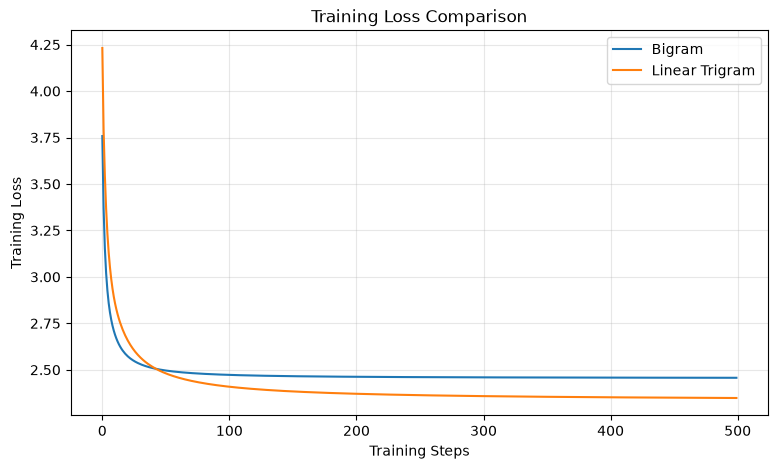

In [7]:
best_bigram = min(bigram_results, key=lambda x: x["dev_loss_bigram"])
best_trigram = min(trigram_results, key=lambda x: x["dev_loss_trigram"])


best_bigram_df = pd.DataFrame([best_bigram])
best_trigram_df = pd.DataFrame([best_trigram])

display(best_bigram_df[[
    "learning_rate", "steps", "reg_strength",
    "train_loss_bigram", "dev_loss_bigram"
]])

display(best_trigram_df[[
    "learning_rate", "steps", "reg_strength",
    "train_loss_trigram", "dev_loss_trigram"
]])

plt.figure(figsize=(9, 5))

plt.plot(best_bigram["loss_history_bigram"], label="Bigram")
plt.plot(best_trigram["loss_history_trigram"], label="Linear Trigram")

plt.xlabel("Training Steps")
plt.ylabel("Training Loss")
plt.title("Training Loss Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 7. Final Evaluation

In [8]:
bigram_test_loss = run_test(best_bigram["W_bigram"],test_words=test_words,block_size=1)
trigram_test_loss = run_test(best_trigram["W_trigram"], test_words=test_words, block_size=2)

print(f"Bigram Test Loss: {bigram_test_loss:.4f}")
print(f"Trigram Test Loss: {trigram_test_loss:.4f}")

Bigram Test Loss: 2.4608
Trigram Test Loss: 2.3506


## 8. Text Generation

In [9]:
g = torch.Generator().manual_seed(2147483647)

print(f"{'#':<4} {'Bigram':<20} {'Trigram'}")
print("-" * 40)

for i in range(1, 11):
    bigram_name = generate_names(best_bigram["W_bigram"], block_size=1, generator=g)
    trigram_name = generate_names(best_trigram["W_trigram"], block_size=2, generator=g)

    print(f"{i:<4} {bigram_name:<20} {trigram_name}")

#    Bigram               Trigram
----------------------------------------
1    dexze.               morlyurailaziaydamel
2    jimittain.           lusan.
3    ka.                  da.
4    staiyaubrtthrigotai. morielliausie.
5    teda.                kaleyla.
6    sade.                enkavirny.
7    fobspehinivenvorhlas ckasdr.
8    br.                  jol.
9    pen.                 aisan.
10   ja.                  fen.


## 9. Conclusions

The Linear Trigram performed better than the Bigram, with a test loss of 2.3506 compared to 2.4608.

The best configurations were:
- **Bigram:** Learning rate of 50, 500 steps, no regularization.
- **Linear Trigram:** Learning rate of 20, 500 steps, no regularization.

Both models had similar validation and test losses, so there wasn't a noticeable gap between them.

The Trigram achieved a lower loss, but looking at the generated names, both models still produced some unrealistic results.